In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats import probplot # For QQ Plot

df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

# --- Preliminary Data Cleaning ---
# Renaming 'stars' column for consistency and dropping NaNs in key columns.
df = df.rename(columns={'stars': 'rating'})
df_cleaned = df.dropna(subset=['price', 'rating', 'category', 'isBestSeller']).copy()

# Ensure 'rating' is treated as numeric (if not already)
df_cleaned['rating'] = pd.to_numeric(df_cleaned['rating'], errors='coerce')

# Filter out non-rated products (rating == 0.00) as established in Part I
df_cleaned = df_cleaned[df_cleaned['rating'] > 0.00]

print(f"Cleaned DataFrame shape after initial filtering: {df_cleaned.shape}")
print(df.head())

Cleaned DataFrame shape after initial filtering: (1218010, 9)
   uid        asin                                              title  rating  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...     4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...     4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...     4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...     4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...     4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


In [3]:
# 1. Create a crosstab between category and isBestSeller status
crosstab_raw = pd.crosstab(df_cleaned['category'], df_cleaned['isBestSeller'])
print("--- Raw Crosstab (Category vs. isBestSeller) ---")
print(crosstab_raw)

# 2. Calculate the proportion of best-sellers for each category
# This calculates the proportion of True (isBestSeller) for each category.
crosstab_proportion = pd.crosstab(df_cleaned['category'], df_cleaned['isBestSeller'], normalize='index') * 100

# Extract the 'True' column (Best-Seller proportion) and sort
best_seller_proportions = crosstab_proportion[True].sort_values(ascending=False)

print("\n--- Top 10 Categories by Best-Seller Proportion ---")
print(best_seller_proportions.head(10))


--- Raw Crosstab (Category vs. isBestSeller) ---
isBestSeller                    False  True 
category                                    
3D Printers                       160      1
3D Printing & Scanning            143      2
Abrasive & Finishing Products     229      5
Action Cameras                    564      1
Adapters                          240      3
...                               ...    ...
Wind Instruments                  116      7
Window Treatments                 220      5
Women                           17274    212
Women's Sports & Outdoor Shoes   1769     20
eBook Readers & Accessories       109      0

[296 rows x 2 columns]

--- Top 10 Categories by Best-Seller Proportion ---
category
Material Handling Products        12.121212
Smart Home Security & Lighting     7.792208
Test & Measurement                 6.000000
Grocery                            5.835432
Health & Personal Care             5.774663
Wind Instruments                   5.691057
Professional Med

In [8]:
# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(crosstab_raw)

print("\n--- Chi-square Test Results (Best-Seller vs. Category) ---")
print(f"Chi-square Statistic: {chi2:.2f}")
print(f"P-value: {p_value:.10f}") # P-value close to zero indicates dependence

# Interpretation: If p-value < 0.05, the variables are NOT independent.
# Compute Cramér's V (Measure of Association Strength)
# Cramér's V is calculated from the Chi-square statistic
N = crosstab_raw.sum().sum()
min_dim = min(crosstab_raw.shape) - 1
cramers_v = np.sqrt(chi2 / (N * min_dim))

print(f"Cramér's V: {cramers_v:.4f}")

# Interpretation: 
# V ≈ 0: little to no association
# V > 0.2: moderate association
# V > 0.6: strong association


--- Chi-square Test Results (Best-Seller vs. Category) ---
Chi-square Statistic: 15380.14
P-value: 0.0000000000
Cramér's V: 0.1124


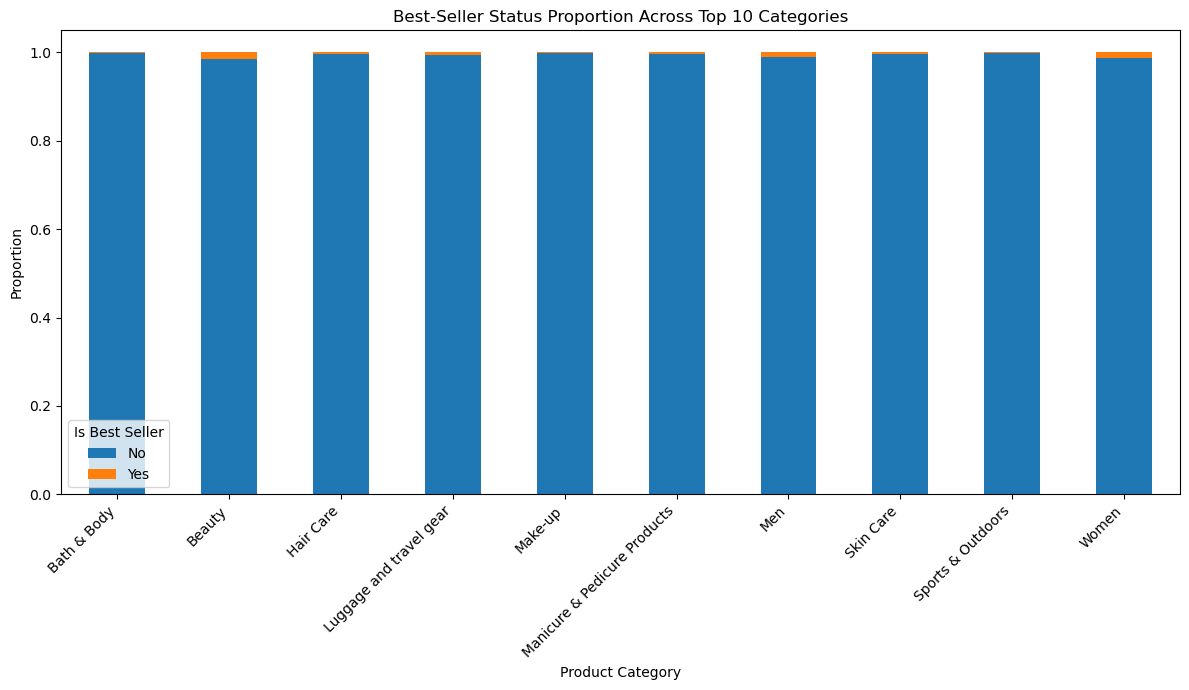

In [9]:
# Filter for the top 10 categories based on count for a readable stacked bar chart
top_10_categories_list = df_cleaned['category'].value_counts().nlargest(10).index.tolist()
df_top_10 = df_cleaned[df_cleaned['category'].isin(top_10_categories_list)].copy()

# Visualize the relationship using a stacked bar chart
# The crosstab is normalized to show proportions
crosstab_plot = pd.crosstab(df_top_10['category'], df_top_10['isBestSeller'], normalize='index')

plt.figure(figsize=(12, 7))
crosstab_plot.plot(kind='bar', stacked=True, color=['#1f77b4', '#ff7f0e'], ax=plt.gca())
plt.title('Best-Seller Status Proportion Across Top 10 Categories')
plt.xlabel('Product Category')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Is Best Seller', labels=['No', 'Yes'])
plt.tight_layout()
plt.show()

In [10]:
# Calculate Q1, Q3, and IQR for the 'price' column
Q1 = df_cleaned['price'].quantile(0.25)
Q3 = df_cleaned['price'].quantile(0.75)
IQR = Q3 - Q1

# Define the boundaries for outlier removal
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the DataFrame to exclude outliers
df_no_outliers = df_cleaned[
    (df_cleaned['price'] >= lower_bound) & 
    (df_cleaned['price'] <= upper_bound)
].copy()

print("\n--- Outlier Removal Summary ---")
print(f"Original records: {len(df_cleaned)}")
print(f"Records after outlier removal (Price): {len(df_no_outliers)}")
print(f"Price range used: £{lower_bound:.2f} to £{upper_bound:.2f}")


--- Outlier Removal Summary ---
Original records: 1218010
Records after outlier removal (Price): 1073373
Price range used: £-29.80 to £73.64


C:\Users\tozes\AppData\Local\Temp\ipykernel_11736\3209280494.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='category', y='price', data=df_violin, inner='quartile', palette='pastel')


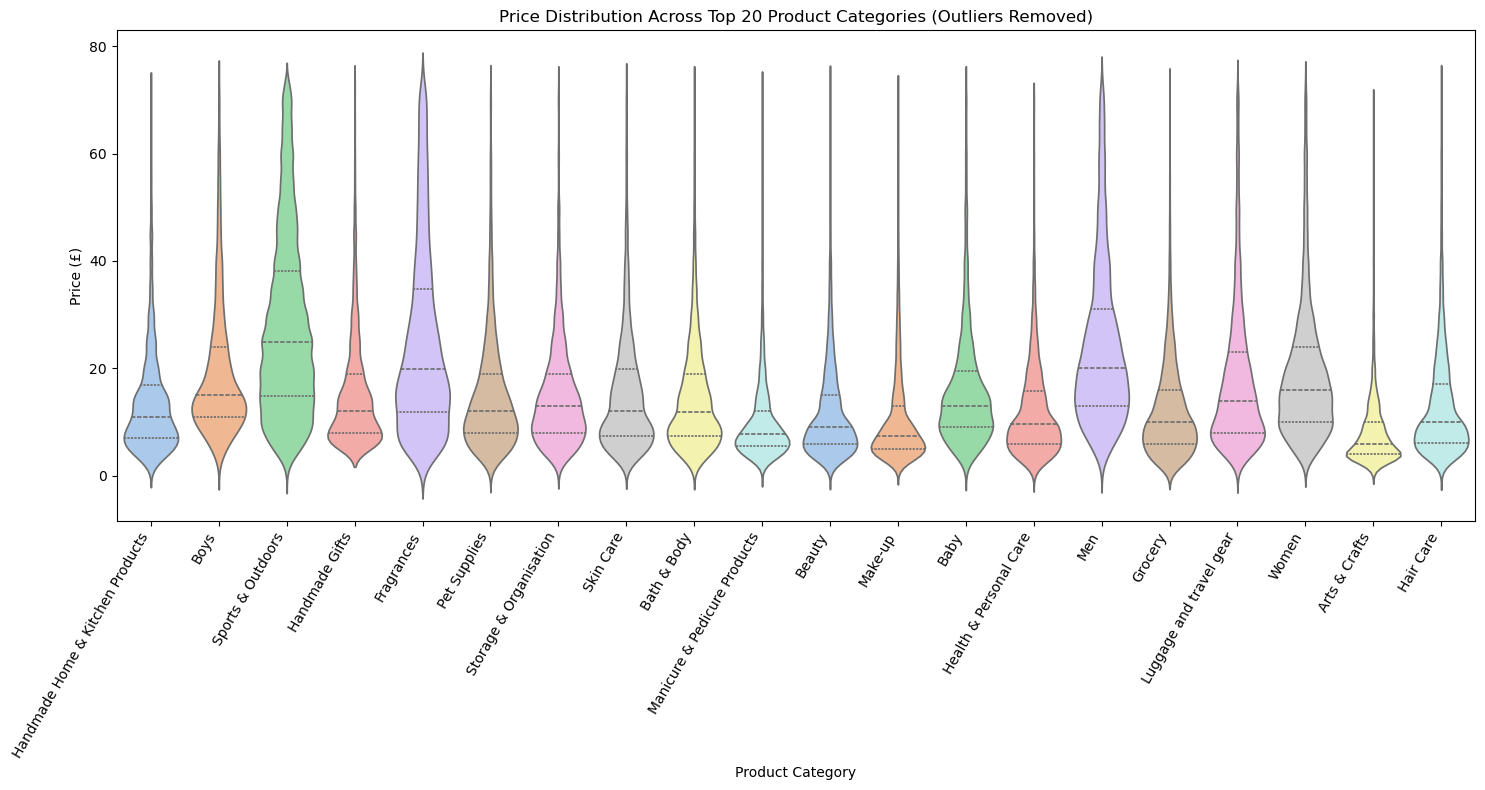


--- Category with Highest Median Price (Full Data) ---
category
Laptops    540.8
Name: price, dtype: float64


In [11]:
# Filter out the top 20 categories based on count for better visualization
top_20_categories_list = df_no_outliers['category'].value_counts().nlargest(20).index.tolist()
df_violin = df_no_outliers[df_no_outliers['category'].isin(top_20_categories_list)].copy()

plt.figure(figsize=(15, 8))
sns.violinplot(x='category', y='price', data=df_violin, inner='quartile', palette='pastel')
plt.title('Price Distribution Across Top 20 Product Categories (Outliers Removed)')
plt.xlabel('Product Category')
plt.ylabel('Price (£)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

# Business Question: Which product category tends to have the highest median price? 
# Use the full df_cleaned dataset (before outlier removal) for this specific question 
# to ensure all categories are considered.
median_prices = df_cleaned.groupby('category')['price'].median().sort_values(ascending=False)
print("\n--- Category with Highest Median Price (Full Data) ---")
print(median_prices.head(1))


--- Top 10 Categories by Highest Average Price (Full Data) ---
category
Laptops               759.360720
Desktop PCs           593.090310
Digital Cameras       498.760017
3D Printers           449.882112
Graphics Cards        441.114753
Projectors            424.937603
Lenses                420.899795
Computer Printers     352.502474
Tablets               349.256482
Home Entertainment    322.735380
Name: price, dtype: float64


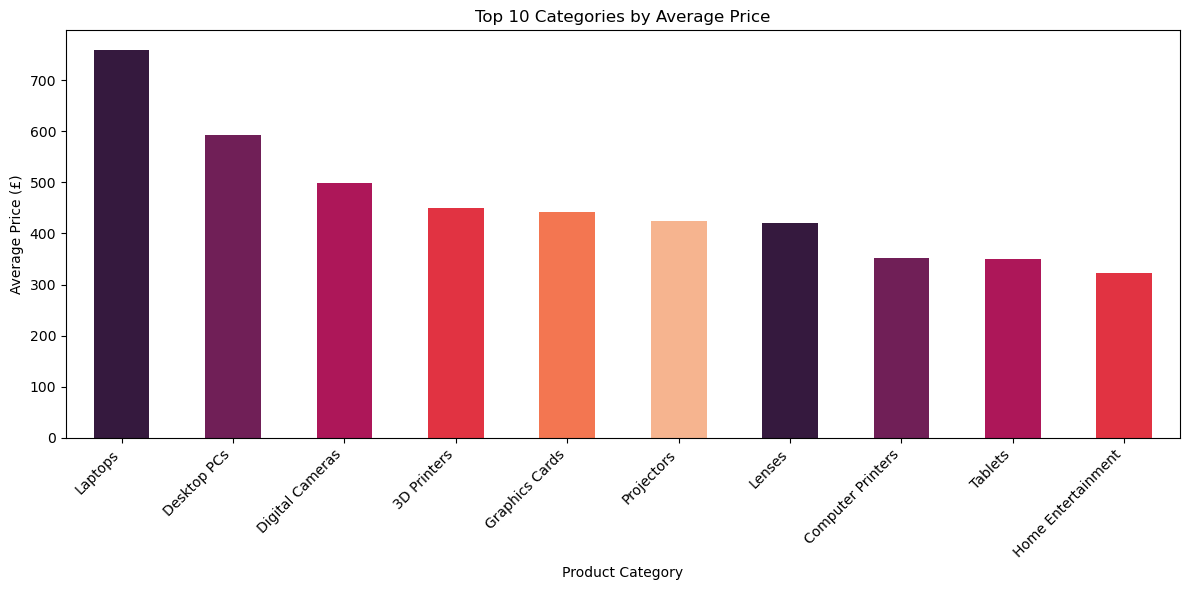

In [12]:
# Group by category and calculate the mean price (using the full cleaned data for complete coverage)
average_prices = df_cleaned.groupby('category')['price'].mean().sort_values(ascending=False)

print("\n--- Top 10 Categories by Highest Average Price (Full Data) ---")
print(average_prices.head(10))

# Create a bar chart comparing the average price for the top 10 categories
plt.figure(figsize=(12, 6))
# Filter the average prices list to plot only the top 10
average_prices.head(10).plot(kind='bar', color=sns.color_palette("rocket"))
plt.title('Top 10 Categories by Average Price')
plt.xlabel('Product Category')
plt.ylabel('Average Price (£)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Business Question: Which product category commands the highest average price?
# (Check the first entry of the average_prices output.)

C:\Users\tozes\AppData\Local\Temp\ipykernel_11736\3939757974.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='rating', data=df_box, palette='cubehelix')


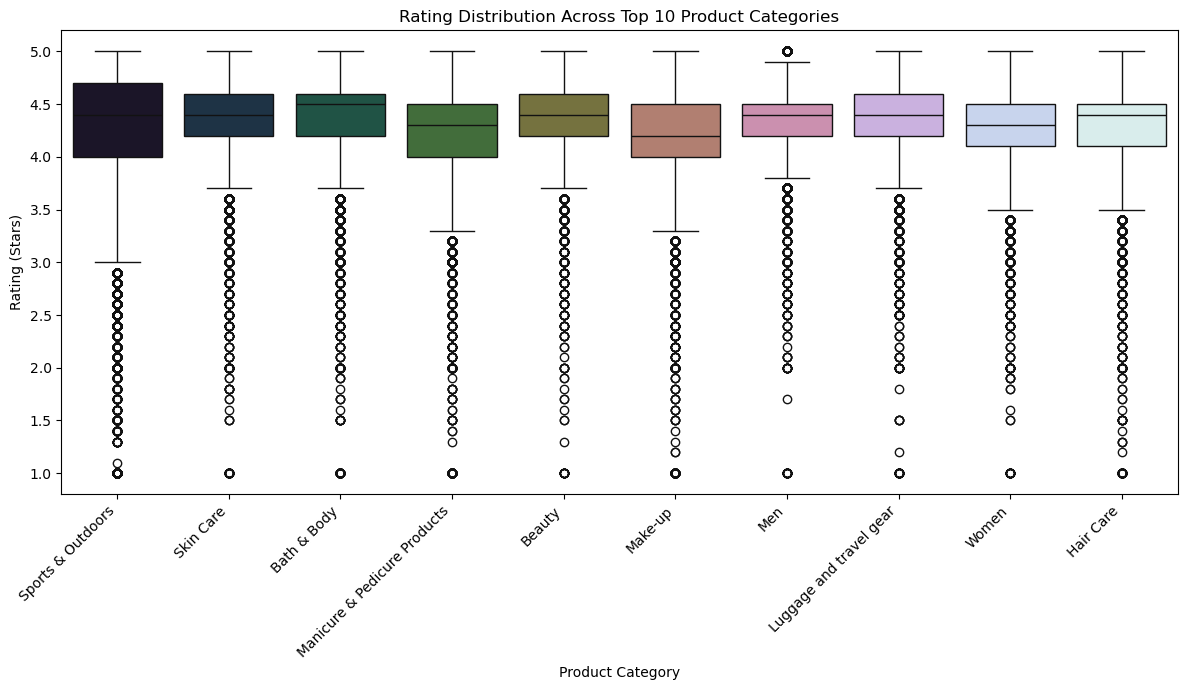


--- Category with Highest Median Rating (Full Data) ---
category
Handmade Artwork    5.0
Name: rating, dtype: float64


In [13]:
# Filter out the top 10 categories based on count for better visualization
top_10_categories_list_rating = df_cleaned['category'].value_counts().nlargest(10).index.tolist()
df_box = df_cleaned[df_cleaned['category'].isin(top_10_categories_list_rating)].copy()

# Visualize the distribution of product ratings based on their category
plt.figure(figsize=(12, 7))
sns.boxplot(x='category', y='rating', data=df_box, palette='cubehelix')
plt.title('Rating Distribution Across Top 10 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Rating (Stars)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Business Question: Which category tends to receive the highest median rating?
# Use the full df_cleaned dataset.
median_ratings = df_cleaned.groupby('category')['rating'].median().sort_values(ascending=False)
print("\n--- Category with Highest Median Rating (Full Data) ---")
print(median_ratings.head(1))

In [14]:
# Calculate the correlation coefficient between price and rating
correlation_pr = df_cleaned['price'].corr(df_cleaned['rating'])

# Calculate the correlation coefficient using the no-outlier data for comparison
correlation_pr_no_outlier = df_no_outliers['price'].corr(df_no_outliers['rating'])

print("\n--- Correlation Results (Price vs. Rating) ---")
print(f"Correlation (Full Data): {correlation_pr:.4f}")
print(f"Correlation (No Outliers): {correlation_pr_no_outlier:.4f}")

# Business Insight: Is there a significant correlation?
# (Correlation near 0 means no linear relationship. Compare the two results.)


--- Correlation Results (Price vs. Rating) ---
Correlation (Full Data): -0.0049
Correlation (No Outliers): 0.0105


There is no significant linear correlation between product price and rating (stars) on Amazon UK.

Near-Zero Coefficient: Both coefficients (with and without outliers) are extremely close to zero, meaning that product price is not a predictor of how well it will be rated, and vice versa.

Why is it zero? In Unidimensional Analysis, we found that ratings are highly consistent (low STD) and concentrated around 4.4 - 4.5. When the variation in one variable (Rating) is very low, it cannot vary relative to the other variable (Price), which has enormous variation.

Business Insight: Customers on Amazon UK rate products based on perceived quality relative to what they expect, not on absolute price. A £1000 product is not, on average, rated more favorably than a £10 product.

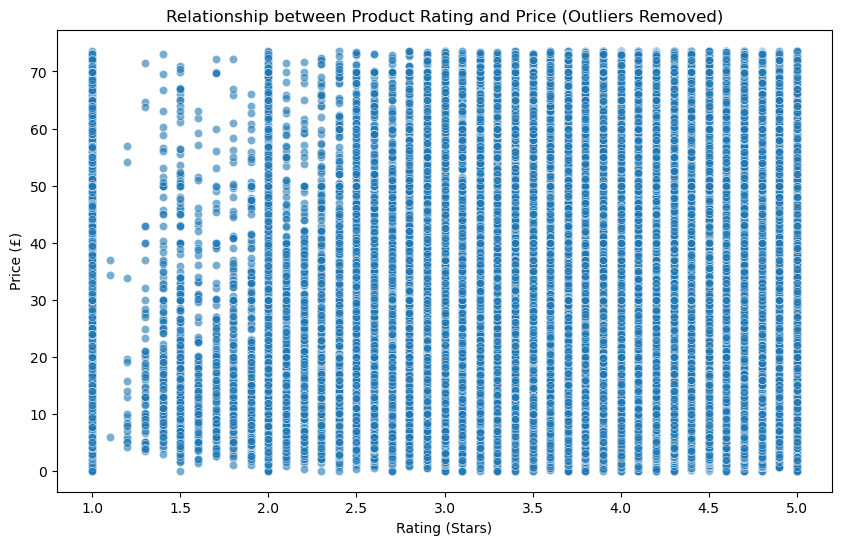

In [15]:
# 1. Scatter Plot (using data without outliers for clarity)
plt.figure(figsize=(10, 6))
sns.scatterplot(x='rating', y='price', data=df_no_outliers, alpha=0.6)
plt.title('Relationship between Product Rating and Price (Outliers Removed)')
plt.xlabel('Rating (Stars)')
plt.ylabel('Price (£)')
plt.show()


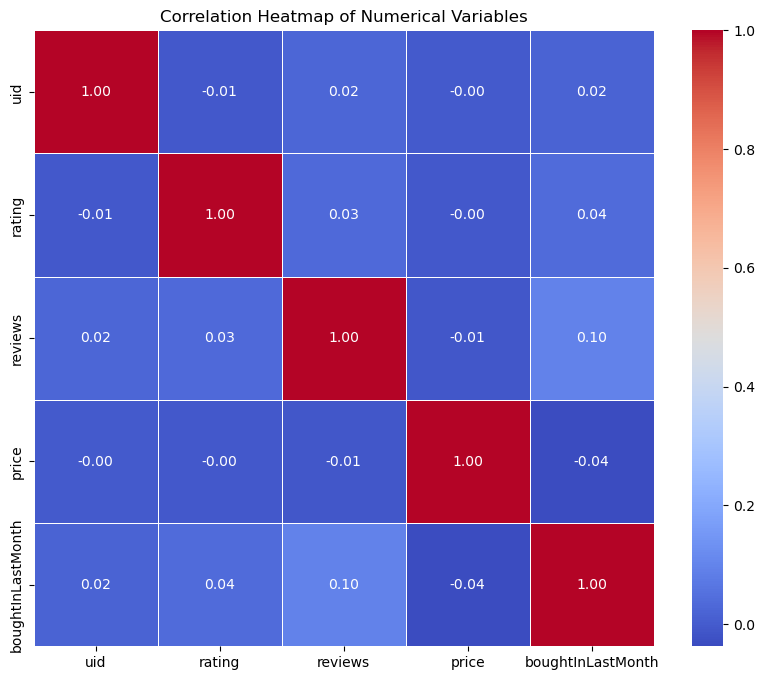

In [16]:
# 2. Correlation Heatmap (using the full cleaned data)
# Select only the numerical columns for correlation calculation
numerical_df = df_cleaned.select_dtypes(include=[np.number])
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

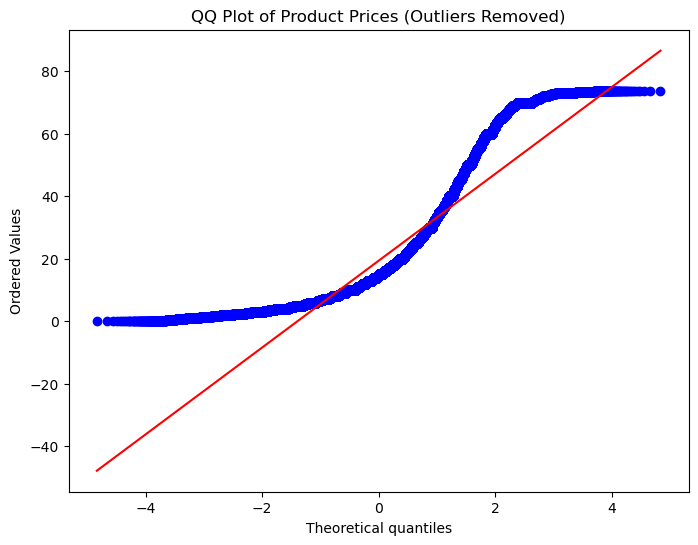

In [17]:
# 3. QQ Plot (To examine if product prices typically follow a normal distribution)
# Use data without outliers for a more meaningful QQ plot
plt.figure(figsize=(8, 6))
probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title('QQ Plot of Product Prices (Outliers Removed)')
plt.show()


Final Analysis of Visualizations
1. Scatter Plot (Relationship between Product Rating and Price)
Graph: The graph shows a dense vertical mass of points. Prices range from £0 to £70 (the limit without outliers), but ratings (X-axis) appear as vertical lines at almost all values ​​from 1.0 to 5.0.

Confirmation: The uniform vertical distribution of points at each rating level visually confirms the zero linear correlation (-0.0049 / 0.0105) between price and rating. The price does not consistently increase or decrease with increasing rating.

2. Correlation Heatmap of Numerical Variables
Graph: The heatmap shows the correlation between all numerical variables.

Confirmation: The correlation cell between rating and price has a value of 0.03 (or 0.02 / -0.00 depending on the axis order), which is very low. This reinforces the conclusion that there is no linear relationship between prices and customer satisfaction.

Other Insights: Note the correlation between reviews and boughtInLastMonth (0.10). Although low, it is the strongest (positive) correlation and suggests that products with more reviews tend to be purchased more frequently.

3. QQ Plot of Product Prices (Outliers Removed)
Graph: The QQ Plot compares the quantiles of the price distribution with the quantiles of a normal distribution. The red straight line represents the normal distribution.

Confirmation: The curve of blue dots deviates significantly from the red line (especially in the tails, flattening at the extremes).

Insight: This confirms that the price distribution is not normal, even after removing outliers. It has thinner tails and a flatter center than a Gaussian distribution.
